Training Days: 47, Testing Days: 62
Linear MAE:        175.59
Random Forest MAE: 102.67


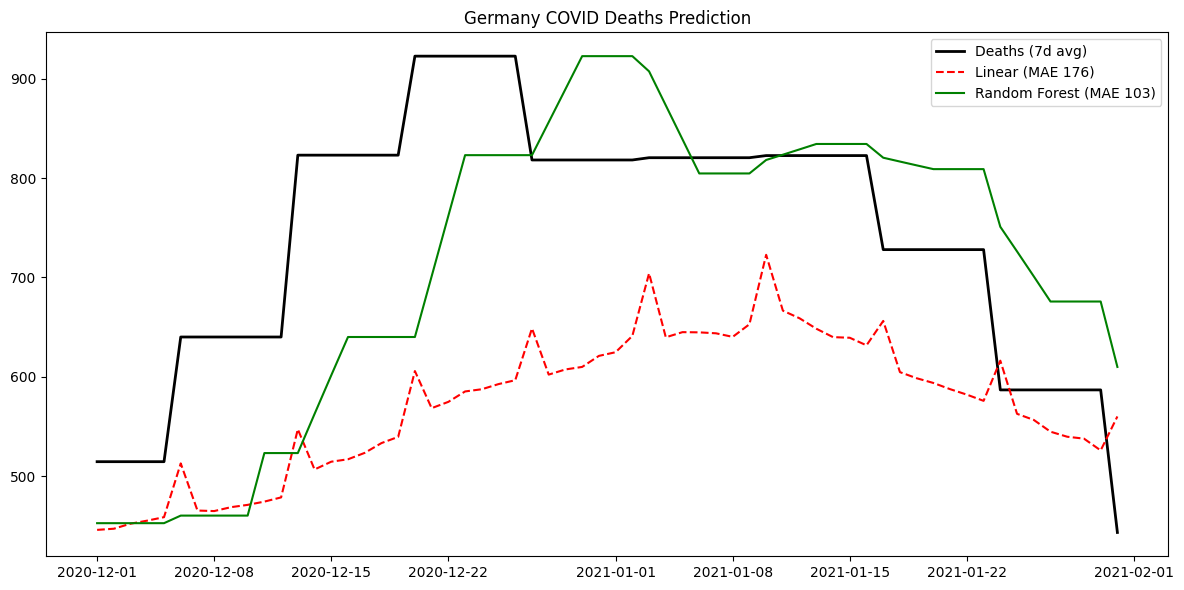

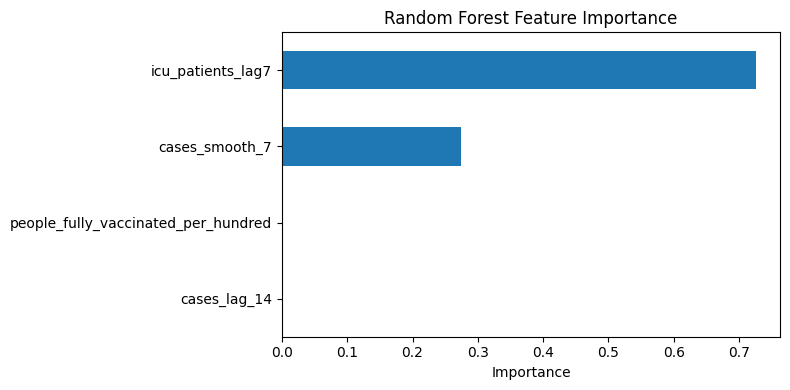

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


WINDOW = 7
EPS = 1e-6  
# --------------------------------------------------
# 1. LOAD & PREP DATA
# --------------------------------------------------
url = "data/compact.csv"
df = pd.read_csv(url)

df['date'] = pd.to_datetime(df['date'])
df = (
    df[df['country'] == 'Germany']
    .set_index('date')
    .sort_index()
)

df = df.loc['2020-10-01':'2022-01-31', [
    'new_cases',
    'new_deaths',
    'people_fully_vaccinated_per_hundred',
    'stringency_index',
    'reproduction_rate',
    'icu_patients'

]]

# forward-fill vaccination data (no leakage)
df['people_fully_vaccinated_per_hundred'] = (
    df['people_fully_vaccinated_per_hundred'].ffill().fillna(0)
)

# --------------------------------------------------
# 2. FEATURE ENGINEERING (LEAKAGE-SAFE)
# --------------------------------------------------
df['cases_lag_14'] = df['new_cases'].shift(14)
df['cases_smooth_7'] = df['new_cases'].rolling(7).mean()
df['deaths_smooth_7'] = df['new_deaths'].rolling(7).mean()
df['icu_patients_lag7'] = df["icu_patients"].shift(7)

# --------------------------------------------------
# 3. MODEL DATASET
# --------------------------------------------------
features = [
    'cases_lag_14',
    'cases_smooth_7',
    'people_fully_vaccinated_per_hundred',
    # 'stringency_index',
    # 'reproduction_rate',
    'icu_patients_lag7'
]

target = 'deaths_smooth_7'

df_model = df[features + [target]].dropna()

# --------------------------------------------------
# 4. TIME-BASED SPLIT
# --------------------------------------------------
cutoff = "2020-12-01"

train = df_model[df_model.index < cutoff]
test  = df_model.loc[cutoff:"2021-01-31"]

X_train, y_train = train[features], train[target]
X_test, y_test   = test[features], test[target]

print(f"Training Days: {len(X_train)}, Testing Days: {len(X_test)}")

# --------------------------------------------------
# 5. BASELINE: LINEAR REGRESSION
# --------------------------------------------------
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, pred_lr)

# --------------------------------------------------
# 6. RANDOM FOREST
# --------------------------------------------------
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
)

rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)


def scaling_pred(prediction, test):
    scaled_pred = np.zeros_like(prediction)
    for t in range(len(prediction)):
        # Not touching the prediction because of the window
        if t < WINDOW+3:
            scaled_pred[t] = prediction[t]
        else:
            # Calculating the mean error for Window-3 : Window
            y_obs_window = test[t-WINDOW-3:t-WINDOW]
            y_pred_window = prediction[t-WINDOW-3:t-WINDOW]

            alpha_t = (
                np.mean(y_obs_window)
                / (np.mean(y_pred_window) + EPS)
            )

            # Scaling each day for the error
            scaled_pred[t] = alpha_t * prediction[t]
    return scaled_pred


scaled_pred_rf = scaling_pred(pred_rf, y_test)
    



mae_rf = mean_absolute_error(y_test, scaled_pred_rf)

print(f"Linear MAE:        {mae_lr:.2f}")
print(f"Random Forest MAE: {mae_rf:.2f}")

# --------------------------------------------------
# 7. VISUAL COMPARISON
# --------------------------------------------------
plt.figure(figsize=(12, 6))
plt.plot(test.index, y_test, color="black", label="Deaths (7d avg)", linewidth=2)
plt.plot(test.index, pred_lr, color="red", linestyle="--",
         label=f"Linear (MAE {mae_lr:.0f})")
plt.plot(test.index, scaled_pred_rf, color="green",
         label=f"Random Forest (MAE {mae_rf:.0f})")

plt.title("Germany COVID Deaths Prediction")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. FEATURE IMPORTANCE (RF)
# --------------------------------------------------
importances = (
    pd.Series(rf.feature_importances_, index=features)
    .sort_values()
)

plt.figure(figsize=(8, 4))
importances.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [6]:
from xgboost import XGBRegressor

# --------------------------------------------------
# 6B. XGBOOST (FINAL MODEL)
# --------------------------------------------------
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

xgb.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

pred_xgb = xgb.predict(X_test)

scaled_pred_xgb = scaling_pred(pred_xgb, y_test)


mae_xgb = mean_absolute_error(y_test, scaled_pred_xgb)

print(f"XGBoost MAE:       {mae_xgb:.2f}")


XGBoost MAE:       101.06


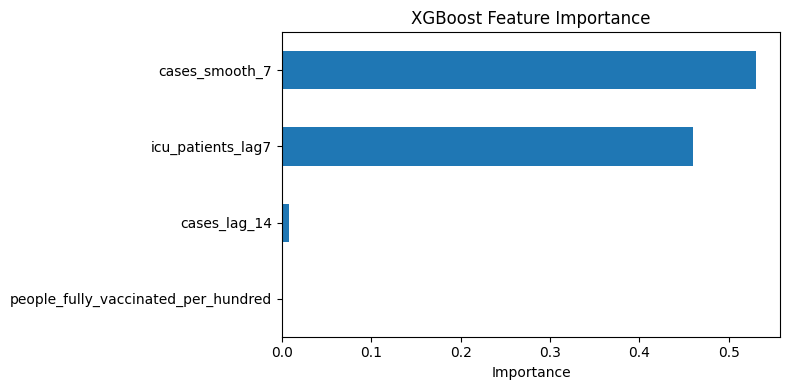

In [7]:
importances_xgb = (
    pd.Series(xgb.feature_importances_, index=features)
    .sort_values()
)

plt.figure(figsize=(8, 4))
importances_xgb.plot(kind="barh")
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


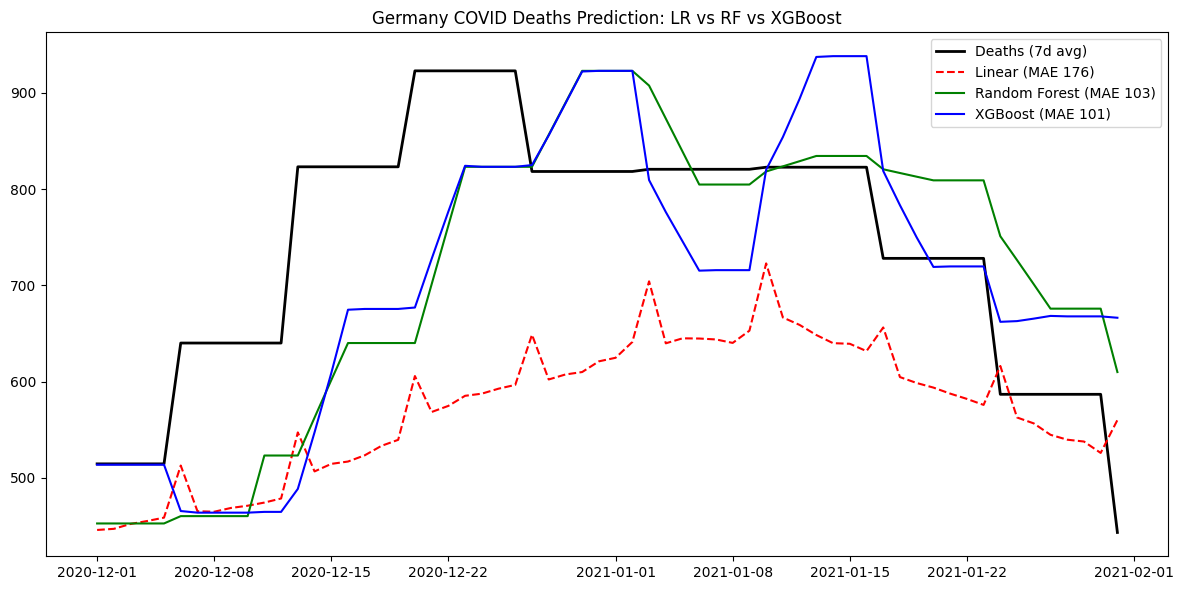

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(test.index, y_test, color="black", label="Deaths (7d avg)", linewidth=2)
plt.plot(test.index, pred_lr, color="red", linestyle="--",
         label=f"Linear (MAE {mae_lr:.0f})")
plt.plot(test.index, scaled_pred_rf, color="green",
         label=f"Random Forest (MAE {mae_rf:.0f})")
plt.plot(test.index, scaled_pred_xgb, color="blue",
         label=f"XGBoost (MAE {mae_xgb:.0f})")

plt.title("Germany COVID Deaths Prediction: LR vs RF vs XGBoost")
plt.legend()
plt.tight_layout()
plt.show()


## FORECAST

Training Days: 412, Testing Days: 62
Linear MAE:        345.04
Random Forest MAE: 52.73


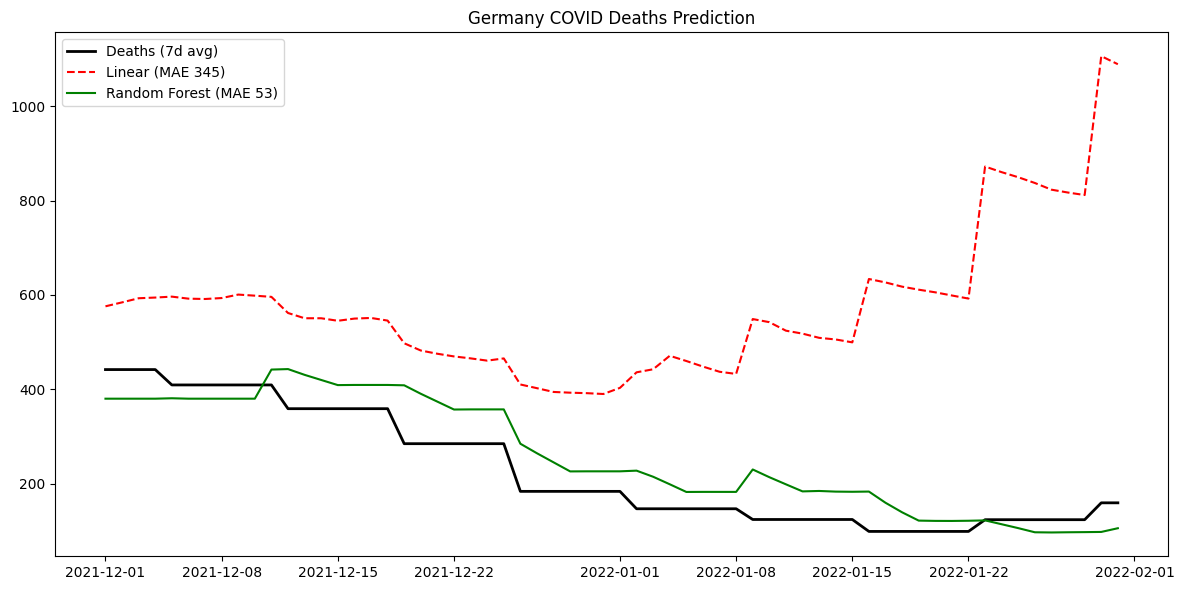

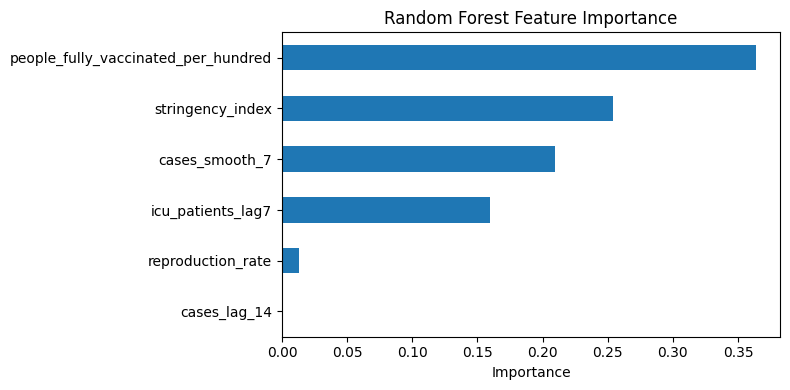

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

FC_WINDOW = 7
FC_EPS = 1e-6  

# --------------------------------------------------
# 1. LOAD & PREP DATA
# --------------------------------------------------
fc_url = "data/compact.csv"
fc_df = pd.read_csv(fc_url)

fc_df['date'] = pd.to_datetime(fc_df['date'])
fc_df = (
    fc_df[fc_df['country'] == 'Germany']
    .set_index('date')
    .sort_index()
)

fc_df = fc_df.loc['2020-10-01':'2022-01-31', [
    'new_cases',
    'new_deaths',
    'people_fully_vaccinated_per_hundred',
    'stringency_index',
    'reproduction_rate',
    'icu_patients'
]]

# forward-fill vaccination data (no leakage)
fc_df['people_fully_vaccinated_per_hundred'] = (
    fc_df['people_fully_vaccinated_per_hundred'].ffill().fillna(0)
)

# --------------------------------------------------
# 2. FEATURE ENGINEERING (LEAKAGE-SAFE)
# --------------------------------------------------
fc_df['cases_lag_14'] = fc_df['new_cases'].shift(14)
fc_df['cases_smooth_7'] = fc_df['new_cases'].rolling(7).mean()
fc_df['deaths_smooth_7'] = fc_df['new_deaths'].rolling(7).mean()
fc_df['icu_patients_lag7'] = fc_df['icu_patients'].shift(7)

# --------------------------------------------------
# 3. MODEL DATASET
# --------------------------------------------------
fc_features = [
    'cases_lag_14',
    'cases_smooth_7',
    'people_fully_vaccinated_per_hundred',
    'stringency_index',
    'reproduction_rate',
    'icu_patients_lag7'
]

fc_target = 'deaths_smooth_7'

fc_df_model = fc_df[fc_features + [fc_target]].dropna()

# --------------------------------------------------
# 4. TIME-BASED SPLIT
# --------------------------------------------------
fc_cutoff = "2021-12-01"

fc_train = fc_df_model[fc_df_model.index < fc_cutoff]
fc_test  = fc_df_model.loc[fc_cutoff:"2022-01-31"]

X_train_fc, y_train_fc = fc_train[fc_features], fc_train[fc_target]
X_test_fc, y_test_fc   = fc_test[fc_features], fc_test[fc_target]

print(f"Training Days: {len(X_train_fc)}, Testing Days: {len(X_test_fc)}")

# --------------------------------------------------
# 5. BASELINE: LINEAR REGRESSION
# --------------------------------------------------
fc_lr = LinearRegression()
fc_lr.fit(X_train_fc, y_train_fc)
fc_pred_lr = fc_lr.predict(X_test_fc)
fc_mae_lr = mean_absolute_error(y_test_fc, fc_pred_lr)

# --------------------------------------------------
# 6. RANDOM FOREST
# --------------------------------------------------
fc_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
)

fc_rf.fit(X_train_fc, y_train_fc)
fc_pred_rf = fc_rf.predict(X_test_fc)

def fc_scaling_pred(prediction, truth):
    scaled_pred = np.zeros_like(prediction)
    for t in range(len(prediction)):
        if t < FC_WINDOW + 3:
            scaled_pred[t] = prediction[t]
        else:
            y_obs_window = truth[t-FC_WINDOW-3:t-FC_WINDOW]
            y_pred_window = prediction[t-FC_WINDOW-3:t-FC_WINDOW]

            alpha_t = (
                np.mean(y_obs_window)
                / (np.mean(y_pred_window) + FC_EPS)
            )
            scaled_pred[t] = alpha_t * prediction[t]
    return scaled_pred

fc_scaled_pred_rf = fc_scaling_pred(fc_pred_rf, y_test_fc)
fc_mae_rf = mean_absolute_error(y_test_fc, fc_scaled_pred_rf)

print(f"Linear MAE:        {fc_mae_lr:.2f}")
print(f"Random Forest MAE: {fc_mae_rf:.2f}")

# --------------------------------------------------
# 7. VISUAL COMPARISON
# --------------------------------------------------
plt.figure(figsize=(12, 6))
plt.plot(fc_test.index, y_test_fc, color="black", label="Deaths (7d avg)", linewidth=2)
plt.plot(fc_test.index, fc_pred_lr, color="red", linestyle="--",
         label=f"Linear (MAE {fc_mae_lr:.0f})")
plt.plot(fc_test.index, fc_scaled_pred_rf, color="green",
         label=f"Random Forest (MAE {fc_mae_rf:.0f})")

plt.title("Germany COVID Deaths Prediction")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. FEATURE IMPORTANCE (RF)
# --------------------------------------------------
fc_importances = (
    pd.Series(fc_rf.feature_importances_, index=fc_features)
    .sort_values()
)

plt.figure(figsize=(8, 4))
fc_importances.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [12]:
from xgboost import XGBRegressor

# --------------------------------------------------
# 6B. XGBOOST (FINAL MODEL)
# --------------------------------------------------
fc_xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

fc_xgb.fit(
    X_train_fc,
    y_train_fc,
    eval_set=[(X_test_fc, y_test_fc)],
    verbose=False
)

fc_pred_xgb = fc_xgb.predict(X_test_fc)

fc_scaled_pred_xgb = fc_scaling_pred(fc_pred_xgb, y_test_fc)

fc_mae_xgb = mean_absolute_error(y_test_fc, fc_scaled_pred_xgb)

print(f"XGBoost MAE:       {fc_mae_xgb:.2f}")


XGBoost MAE:       46.44


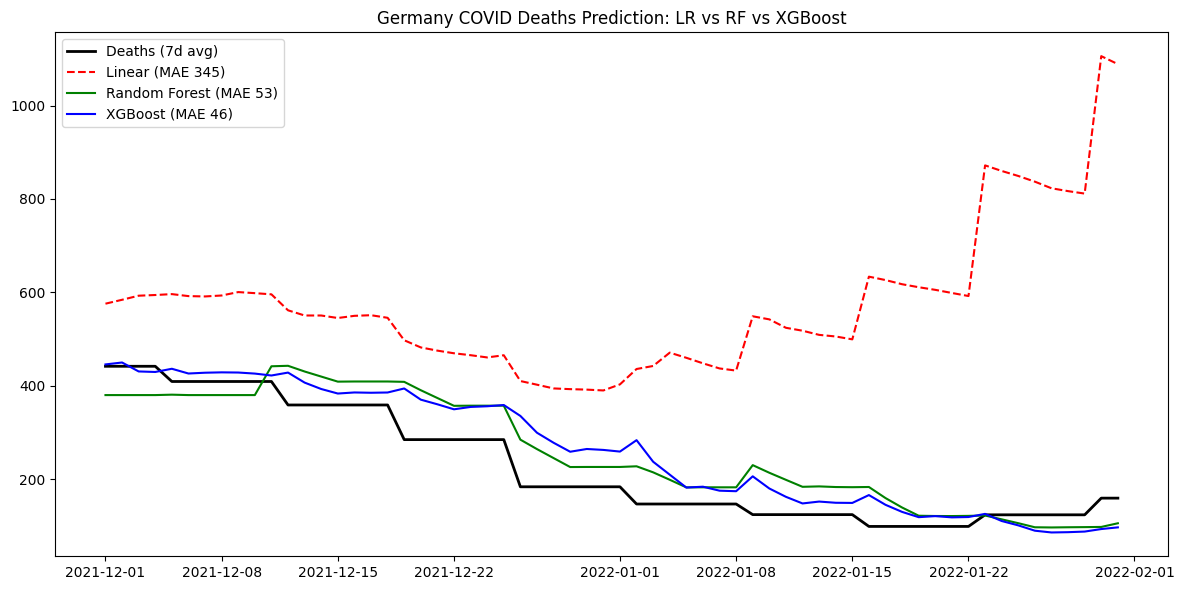

In [13]:
plt.figure(figsize=(12, 6))
plt.plot(fc_test.index, y_test_fc, color="black",
         label="Deaths (7d avg)", linewidth=2)

plt.plot(fc_test.index, fc_pred_lr, color="red", linestyle="--",
         label=f"Linear (MAE {fc_mae_lr:.0f})")

plt.plot(fc_test.index, fc_scaled_pred_rf, color="green",
         label=f"Random Forest (MAE {fc_mae_rf:.0f})")

plt.plot(fc_test.index, fc_scaled_pred_xgb, color="blue",
         label=f"XGBoost (MAE {fc_mae_xgb:.0f})")

plt.title("Germany COVID Deaths Prediction: LR vs RF vs XGBoost")
plt.legend()
plt.tight_layout()
plt.show()


In [14]:
# --------------------------------------------------
# JANUARY 2022 EXPORT (XGBOOST BEST MODEL)
# --------------------------------------------------

# Use XGBOOST (scaled) predictions
fc_pred_best = fc_scaled_pred_xgb

# January 2022 mask
jan_mask = (
    (X_test_fc.index >= "2022-01-01") &
    (X_test_fc.index <= "2022-01-31")
)

jan_dates = X_test_fc.index[jan_mask]
jan_predictions = fc_pred_best[jan_mask]

final_predictions = pd.DataFrame({
    "Date": jan_dates,
    "Region": "Germany",
    "Predicted deaths": jan_predictions,
    "Actual deaths": y_test_fc.loc[jan_dates].values
})

# Round predictions to integers
final_predictions["Predicted deaths"] = (
    final_predictions["Predicted deaths"].round(0).astype(int)
)

# Save CSV (downloadable file)
final_predictions.to_csv(
    "Germany_Jan2022_Predicted_Deaths_XGB.csv",
    index=False
)

print(final_predictions.head())
print(final_predictions.tail())
print(len(final_predictions))  # should be 31
print("File downloaded successfully!")


        Date   Region  Predicted deaths  Actual deaths
0 2022-01-01  Germany               259     183.857143
1 2022-01-02  Germany               284     147.000000
2 2022-01-03  Germany               237     147.000000
3 2022-01-04  Germany               210     147.000000
4 2022-01-05  Germany               182     147.000000
         Date   Region  Predicted deaths  Actual deaths
26 2022-01-27  Germany                86     123.857143
27 2022-01-28  Germany                87     123.857143
28 2022-01-29  Germany                88     123.857143
29 2022-01-30  Germany                93     159.571429
30 2022-01-31  Germany                97     159.571429
31
File downloaded successfully!
